# 05 · Conclusões e insights

**Projeto Integrado: Aprendizado de Máquina aplicado ao Projeto**

Os três modelos respondem às três perguntas do **ciclo comercial** da empresa:

```
  QUEM é o cliente?        →   QUANTO cobrar?          →   VAI FECHAR?
  02 · Agrupamento             04 · Regressão              03 · Classificação
  (K-Means)                    (Regressão Linear)          (Regressão Logística)
```

O segmento descoberto no agrupamento entra como variável nos outros dois modelos. É isso que liga as três análises
num projeto só.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo_graficos as eg

eg.aplicar_estilo()
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)
DIR_PROC = RAIZ / "dados" / "processed"

seg = json.loads((DIR_PROC / "metricas_segmentacao.json").read_text())
cla = json.loads((DIR_PROC / "metricas_classificacao.json").read_text())
reg = json.loads((DIR_PROC / "metricas_regressao.json").read_text())

## 1. Resumo técnico dos modelos

In [2]:
logistica, linear = cla["teste"]["Regressão Logística"], reg["teste"]["Regressão Linear"]
base_reg = reg["teste"]["Baseline (tabela)"]
pd.DataFrame([
    {"Pergunta": "Quem é o cliente?", "Técnica": "Agrupamento", "Algoritmo": "K-Means (k = 4)",
     "Resultado": f"Silhueta {seg['silhueta']:.2f} · ARI vs. perfis reais {seg['ari_gabarito']:.2f}",
     "Referência": "Silhueta > 0,25 = estrutura razoável; ARI 0 = acaso"},
    {"Pergunta": "Vai fechar?", "Técnica": "Classificação", "Algoritmo": "Regressão Logística",
     "Resultado": f"AUC {logistica['AUC']:.2f} · acurácia {logistica['Acurácia']:.0%} (teste 2026)",
     "Referência": f"Baseline: AUC 0,50 · acurácia {cla['teste']['Baseline (sempre fecha)']['Acurácia']:.0%}"},
    {"Pergunta": "Quanto cobrar?", "Técnica": "Regressão", "Algoritmo": "Regressão Linear (alvo em log)",
     "Resultado": f"Erro médio {linear['MAPE']:.1%} · R$ {linear['MAE (R$)']:.2f}/unidade",
     "Referência": f"Tabela atual: {base_reg['MAPE']:.1%} · R$ {base_reg['MAE (R$)']:.2f}/unidade"},
]).set_index("Pergunta")

,Técnica,Algoritmo,Resultado,Referência
Pergunta,,,,
Quem é o cliente?,Agrupamento,K-Means (k = 4),Silhueta 0.37 · ARI vs. perfis reais 0.62,"Silhueta > 0,25 = estrutura razoável; ARI 0 = ..."
Vai fechar?,Classificação,Regressão Logística,AUC 0.74 · acurácia 70% (teste 2026),"Baseline: AUC 0,50 · acurácia 61%"
Quanto cobrar?,Regressão,Regressão Linear (alvo em log),Erro médio 4.0% · R$ 3.08/unidade,Tabela atual: 11.7% · R$ 9.01/unidade


**Decisões metodológicas que valem para os três:**
- **Sempre contra um baseline:** o "sempre fecha" na classificação, a tabela de preços atual na regressão e o
  acaso (ARI = 0) no agrupamento.
- **Parcimônia:** nos dois problemas supervisionados, modelos mais complexos (Random Forest, Gradient Boosting)
  foram testados e **não superaram** os lineares. Ficaram os lineares, que são mais fáceis de explicar e de usar.
- **Sem vazamento de dados:** só entram variáveis conhecidas no momento da decisão. A divisão treino/teste é
  temporal na classificação, e o pré-processamento fica dentro de `Pipeline`s.
- **Conferências de robustez:** um segundo algoritmo de agrupamento (hierárquico), validação cruzada e SHAP para
  checar o que o modelo linear não captura.

## 2. Prova real: os modelos redescobriram as regras do simulador?

Os dados vêm de um simulador com regras de negócio **documentadas** (ver [`scripts/gerador_dados.py`](../scripts/gerador_dados.py)).
Os modelos nunca viram essas regras. Comparar o que foi plantado com o que foi encontrado mostra se os
métodos funcionam, e se as conclusões acima são confiáveis.

In [3]:
# Regras plantadas no simulador (multiplicadores de chance = exp(efeito logit); preços = fatores diretos)
plantado = {
    ("Fechamento", "Visita técnica"): (np.exp(0.9), cla["odds"]["Visita técnica (sim × não)"]),
    ("Fechamento", "+1 dia para enviar"): (np.exp(-0.22), cla["odds"]["+1 dia para enviar o orçamento"]),
    ("Fechamento", "Cliente que já fechou antes"): (np.exp(0.6), cla["odds"]["Cliente que já fechou antes"]),
    ("Fechamento", "Origem: Indicação × Google"): (np.exp(0.7), cla["odds"]["Origem: Indicação (× Google)"]),
    ("Fechamento", "Origem: Cliente antigo × Google"): (np.exp(0.8), cla["odds"]["Origem: Cliente antigo (× Google)"]),
    ("Fechamento", "Origem: Facebook × Google"): (np.exp(-0.4), cla["odds"]["Origem: Facebook (× Google)"]),
    ("Fechamento", "Origem: Instagram × Google"): (np.exp(-0.3), cla["odds"]["Origem: Instagram (× Google)"]),
    ("Fechamento", "Origem: Panfleto × Google"): (np.exp(-0.6), cla["odds"]["Origem: Panfleto (× Google)"]),
    ("Preço", "Poços de Caldas × São João"): (1.12, 1 + reg["efeito_cidade"]["Poços de Caldas"] / 100),
    ("Preço", "Águas da Prata × São João"): (1.05, 1 + reg["efeito_cidade"]["Águas da Prata"] / 100),
    ("Preço", "Aguaí × São João"): (0.95, 1 + reg["efeito_cidade"]["Aguaí"] / 100),
    ("Preço", "Itobi × São João"): (0.92, 1 + reg["efeito_cidade"]["Itobi"] / 100),
    ("Preço", "Construtoras × Res. econômico"): (0.90 / 0.97, 1 + reg["efeito_segmento"]["Construtoras e obras grandes"] / 100),
}
prova = pd.DataFrame(plantado, index=["plantado", "encontrado"]).T
prova["mesma direção"] = np.where(np.sign(np.log(prova["plantado"])) == np.sign(np.log(prova["encontrado"])), "✔", "✘")
prova.round(2)

plantado  encontrado mesma direção
Fechamento Visita técnica                       2.46        3.03             ✔
           +1 dia para enviar                   0.80        0.82             ✔
           Cliente que já fechou antes          1.82        1.86             ✔
           Origem: Indicação × Google           2.01        2.38             ✔
           Origem: Cliente antigo × Google      2.23        2.53             ✔
           Origem: Facebook × Google            0.67        0.70             ✔
           Origem: Instagram × Google           0.74        0.66             ✔
           Origem: Panfleto × Google            0.55        0.62             ✔
Preço      Poços de Caldas × São João           1.12        1.13             ✔
           Águas da Prata × São João            1.05        1.05             ✔
           Aguaí × São João                     0.95        0.94             ✔
           Itobi × São João                     0.92        0.92             ✔
           Construtoras × Res. econômico        0.93        0.94             ✔

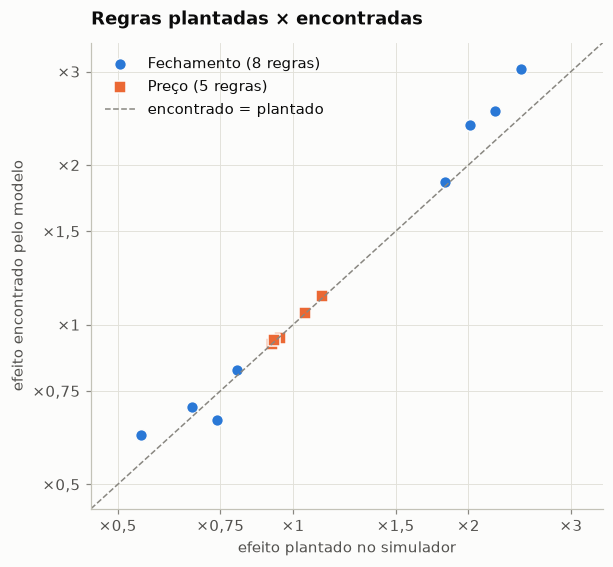

Segmentação: ARI 0.62 entre os segmentos encontrados e os 4 perfis reais.


In [4]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for i, (grupo, marcador) in enumerate([("Fechamento", "o"), ("Preço", "s")]):
    p = prova.loc[grupo]
    ax.scatter(p["plantado"], p["encontrado"], s=60, color=eg.CORES[i], marker=marcador,
               edgecolor=eg.FUNDO, linewidth=1, label=f"{grupo} ({len(p)} regras)")
lim = [0.45, 3.4]
ax.plot(lim, lim, color=eg.TINTA_SUAVE, linestyle="--", linewidth=1, label="encontrado = plantado")
ax.set_xscale("log")
ax.set_yscale("log")
ticks = [0.5, 0.75, 1, 1.5, 2, 3]
ax.set_xticks(ticks, [f"×{t:g}".replace(".", ",") for t in ticks])
ax.set_yticks(ticks, [f"×{t:g}".replace(".", ",") for t in ticks])
ax.minorticks_off()
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_xlabel("efeito plantado no simulador")
ax.set_ylabel("efeito encontrado pelo modelo")
ax.set_title("Regras plantadas × encontradas")
ax.legend(loc="upper left")
plt.show()
print(f"Segmentação: ARI {seg['ari_gabarito']:.2f} entre os segmentos encontrados e os 4 perfis reais.")

**Todas as regras foram recuperadas na direção certa, e quase todas com magnitude muito próxima** (pontos sobre
a diagonal). Os maiores desvios estão nos efeitos de fechamento mais fortes (visita técnica e indicação), que
saíram um pouco **superestimados** (×3,0 encontrado contra ×2,5 plantado). Isso é esperado com ~1.200 orçamentos de treino e
variáveis correlacionadas (quem vem por indicação também tende a ser cliente recorrente). **A direção e a ordem de
grandeza, que é o que orienta as decisões, estão corretas.**

## 3. Plano de ação para a empresa

| # | Ação | Evidência | Origem |
|---|---|---|---|
| 1 | **Oferecer visita técnica** sempre que possível, principalmente em obras médias e grandes | Multiplica a chance de fechar por ~3 | 03 |
| 2 | **Enviar o orçamento em até 48 h** | Cada dia de atraso: −18% na chance de fechar | 03 |
| 3 | **Calcular o preço com "tabela + ajustes"** (cidade, segmento, imóvel, volume) numa planilha | Erro de preço cai de 11,7% para 4,0%; acaba o "a combinar" e acelera o envio (ação 2) | 04 |
| 4 | **Oficializar o preço por cidade** e incluir **Gesso 3D (~R$ 192/m²)** e **Boiserie (~R$ 158/m)** na tabela | Poços de Caldas já paga +13%, Itobi −8% | 04 |
| 5 | **Atendimento dedicado às construtoras** (responsável fixo, pós-obra) | 11% dos clientes = 58% do faturamento | 02 |
| 6 | **Programa de indicação** + **portfólio no Instagram** (sanca, 3D, boiserie) para o alto padrão | Indicação fecha ×2,4 vs. Google; é o canal do alto padrão | 02, 03 |
| 7 | **Google Ads / SEO local** com foco em drywall comercial | Google e site trazem construtoras e comércio | 02 |
| 8 | **Cortar verba de Facebook e panfleto**; **pacote de preço fechado** para gesso liso | Trazem o residencial econômico: 33% dos clientes, 4% do faturamento, fecham menos | 02, 03 |
| 9 | **Teto de desconto de 10%** e desconto por volume por escrito | Acima de 10–12% o desconto não aumenta o fechamento | 03, 04 |
| 10 | **Fila diária de retorno** ordenada pela chance de fechar | Os 20% de maior nota fecham 84%, contra 32% dos de menor nota | 03 |
| 11 | **Registrar o preço de todo serviço fechado** | ~R$ 239 mil em serviços fechados sem preço registrado | 04 |

## 4. Limitações

- **Dados sintéticos.** Os dados vêm de um simulador com regras plausíveis, não da operação real da empresa.
  Os métodos estão validados (seção 2), mas **os números exatos** (×3, −18%, +13%) só valem para a empresa real
  depois de repetir a análise com os dados dela. Todo o pipeline está pronto para isso: basta trocar a fonte.
- **Amostra pequena:** 330 clientes e 1.600 orçamentos. Os efeitos mais fortes são confiáveis; os mais fracos
  (ex.: diferença entre cidades próximas) têm margem de erro relevante.
- **Correlação não é causalidade.** O modelo mostra que orçamentos com visita fecham mais, mas parte disso pode ser
  porque a visita acontece justamente com clientes mais interessados. O ideal é **testar na prática**: oferecer
  visita a um grupo de clientes e comparar com quem não recebeu a oferta (teste A/B).
- **Segmentos calculados com todo o histórico:** o segmento usa o comportamento total do cliente, inclusive
  orçamentos posteriores ao que está sendo previsto no notebook 03. O efeito é pequeno (a importância do segmento ali
  é quase nula), mas, em produção, o segmento deveria ser recalculado só com dados até a data do orçamento.

## 5. Próximos passos

1. **Rodar com dados reais** da empresa (as planilhas e o WhatsApp digitalizados no formato das tabelas do banco).
2. **Teste A/B da visita técnica e do prazo de 48 h**, para medir o efeito causal.
3. **Atualização periódica:** o `make ml` refaz tudo de ponta a ponta (dados → banco → limpeza → 3 modelos).
   Pode rodar todo mês, inclusive agendado no pipeline de infraestrutura do Checkpoint 01.
4. **Painel simples** (ex.: planilha ou Streamlit) com a fila de retorno e a calculadora de preço, para uso diário da equipe.